In [9]:
import spatialdata as sd
from spatialdata_io import xenium

import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc
import squidpy as sq

In [10]:
xenium_path = "/nobackup/proj/comet_smmnfst/xenium_data/output-XETG00465__0103224__Region_1__20260827__130827/"
zarr_path   = "/nobackup/proj/comet_smmnfst/xenium_data/Region_1_20260827.zarr"


sdata = xenium(xenium_path)
sdata.write(zarr_path)

sdata = sd.read_zarr(zarr_path)
sdata

adata = sdata.tables["table"]
adata

adata.obs

adata.obsm["spatial"]


/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/pims/tiff_stack.py:131: UserWarning: <tifffile.TiffPage 0 @16> reading array from closed file
  data = t.asarray()
no parent found for <ome_zarr.reader.Label object at 0x7fec443d5eb0>: None
no parent found for <ome_zarr.reader.Label object at 0x7fec44570410>: None


array([[ 133.47311401,  792.05212402],
       [ 136.28363037,  824.84863281],
       [ 142.74406433,  822.52056885],
       ...,
       [1243.51965332, 3565.60766602],
       [1068.58911133, 3592.45629883],
       [1108.3203125 , 3670.70898438]], shape=(31987, 2))

Negative DNA probe count % : 0.0003184495329141476
Negative decoding count % : 0.0009055908592246073


/scratch/ipykernel_3072581/2089454156.py:52: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata)


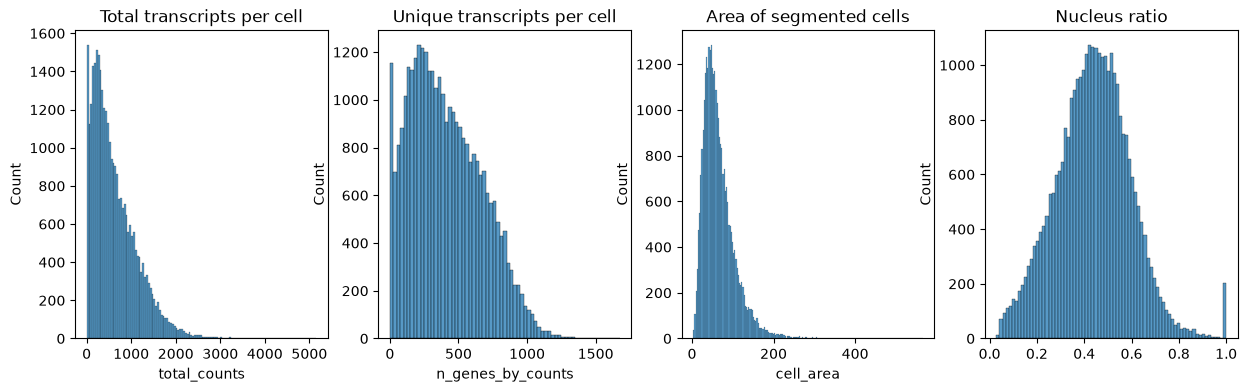

In [11]:
sc.pp.calculate_qc_metrics(adata, percent_top=(10, 20, 50, 150), inplace=True)

cprobes = (
    adata.obs["control_probe_counts"].sum() / adata.obs["total_counts"].sum() * 100
)
cwords = (
    adata.obs["control_codeword_counts"].sum() / adata.obs["total_counts"].sum() * 100
)
print(f"Negative DNA probe count % : {cprobes}")
print(f"Negative decoding count % : {cwords}")

fig, axs = plt.subplots(1, 4, figsize=(15, 4))

axs[0].set_title("Total transcripts per cell")
sns.histplot(
    adata.obs["total_counts"],
    kde=False,
    ax=axs[0],
)

axs[1].set_title("Unique transcripts per cell")
sns.histplot(
    adata.obs["n_genes_by_counts"],
    kde=False,
    ax=axs[1],
)


axs[2].set_title("Area of segmented cells")
sns.histplot(
    adata.obs["cell_area"],
    kde=False,
    ax=axs[2],
)

axs[3].set_title("Nucleus ratio")
sns.histplot(
    adata.obs["nucleus_area"] / adata.obs["cell_area"],
    kde=False,
    ax=axs[3],
)

sc.pp.filter_cells(adata, min_counts=10)
sc.pp.filter_genes(adata, min_cells=5)

adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, inplace=True)
sc.pp.log1p(adata)
sc.pp.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)
sc.tl.leiden(adata)


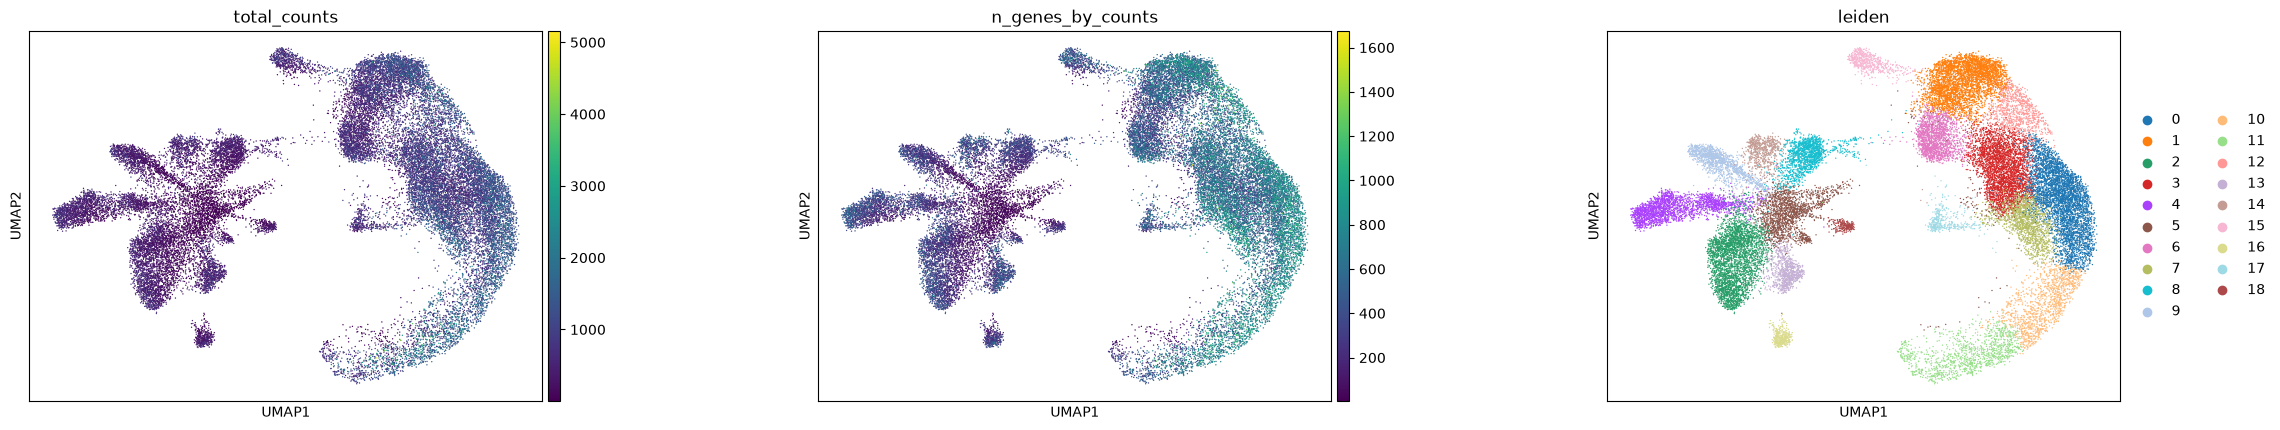

/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


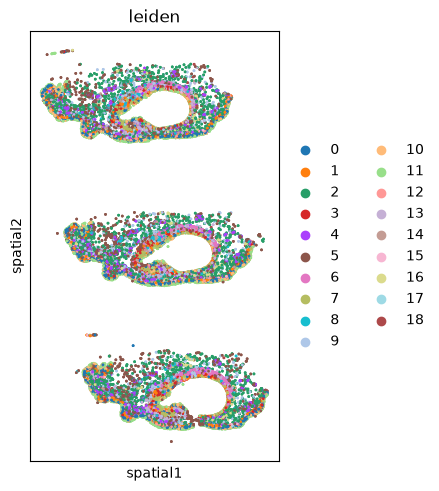

In [12]:
sc.pl.umap(
    adata,
    color=[
        "total_counts",
        "n_genes_by_counts",
        "leiden",
    ],
    wspace=0.4,
)

sq.pl.spatial_scatter(
    adata,
    library_id="spatial",
    shape=None,
    color=[
        "leiden",
    ],
    wspace=0.4,
)


In [13]:
sq.gr.spatial_neighbors(adata, coord_type="generic", delaunay=True)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


/scratch/ipykernel_3072581/3699197381.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata, coord_type="generic", delaunay=True)


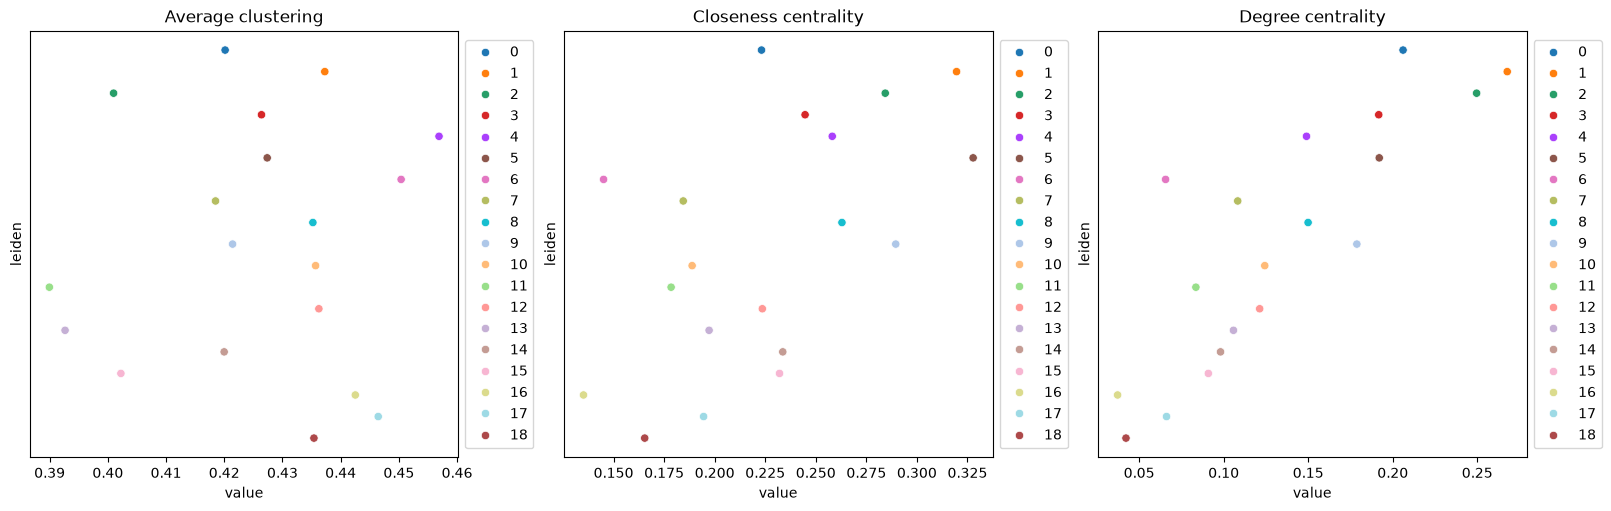

In [14]:
sq.gr.centrality_scores(adata, cluster_key="leiden")

sq.pl.centrality_scores(adata, cluster_key="leiden", figsize=(16, 5))


/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


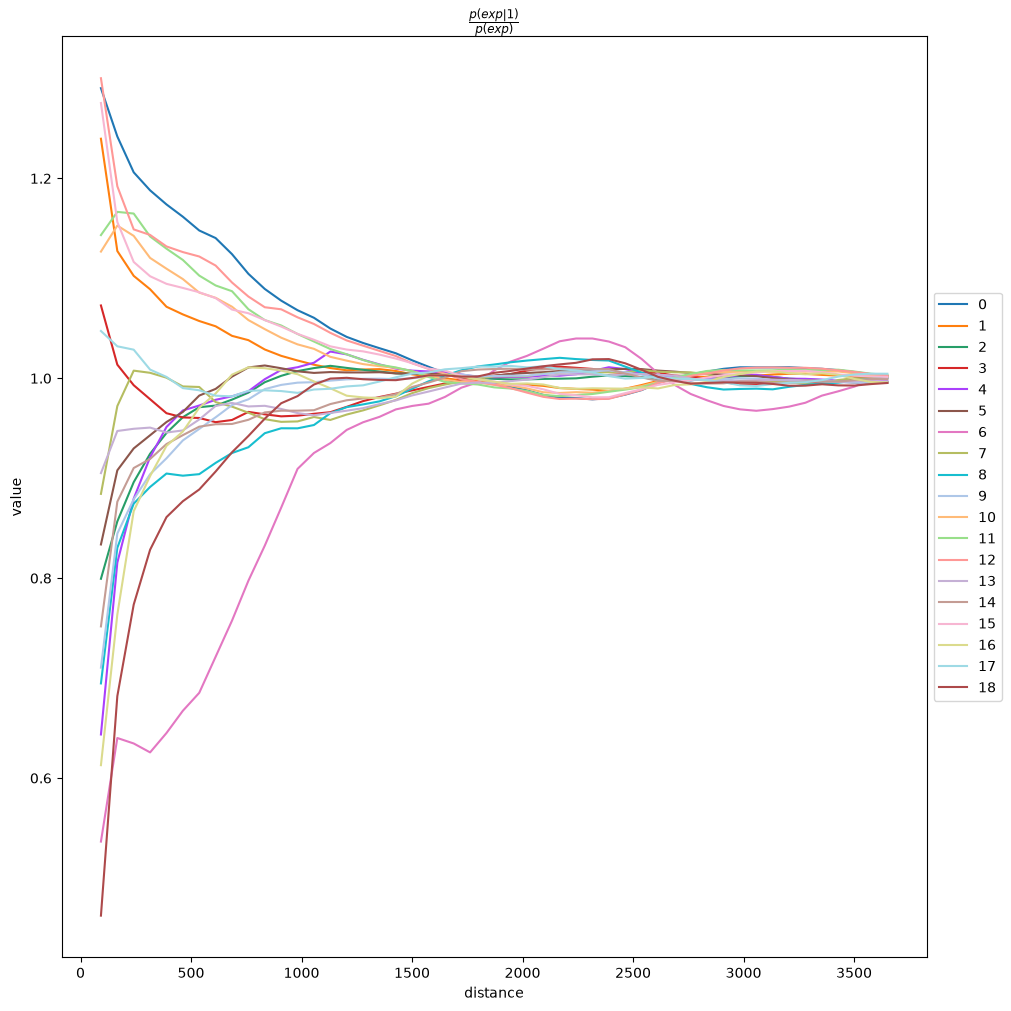

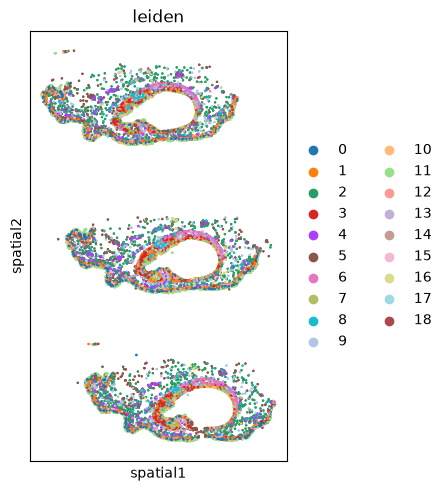

In [16]:
sdata.tables["subsample"] = sc.pp.subsample(adata, fraction=0.5, copy=True)



adata_subsample = sdata.tables["subsample"]
sq.gr.co_occurrence(
    adata_subsample,
    cluster_key="leiden",
)
sq.pl.co_occurrence(
    adata_subsample,
    cluster_key="leiden",
    clusters="1",
    figsize=(10, 10),
)
sq.pl.spatial_scatter(
    adata_subsample,
    color="leiden",
    shape=None,
    size=2,
)


100%|██████████| 1000/1000 [00:02<00:00, 360.61/s]


/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


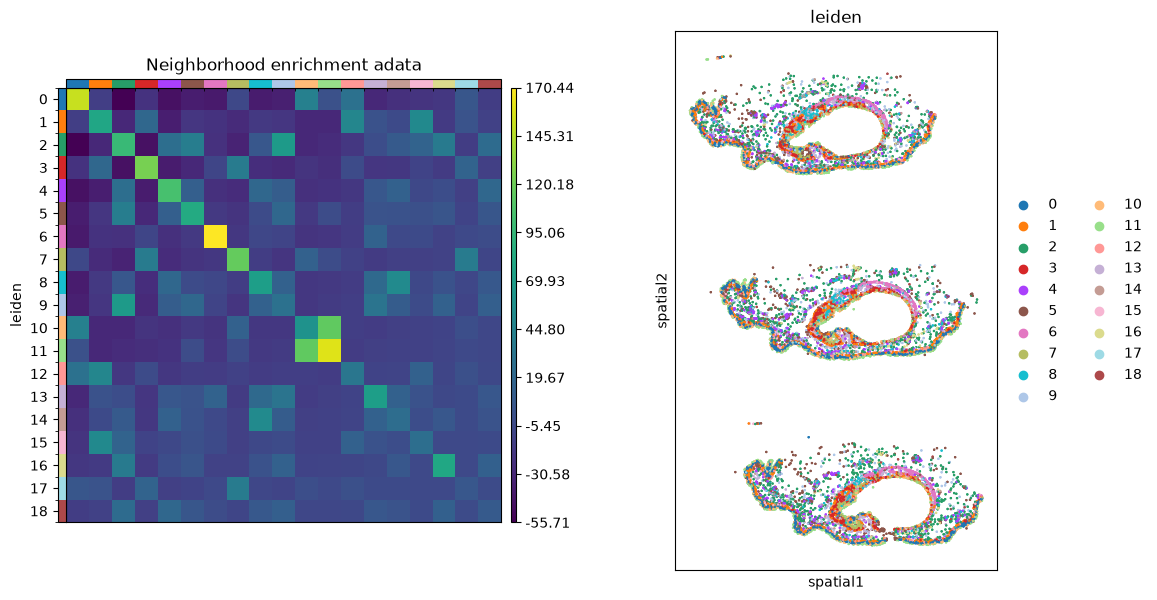

In [17]:
sq.gr.nhood_enrichment(adata, cluster_key="leiden")


fig, ax = plt.subplots(1, 2, figsize=(13, 7))
sq.pl.nhood_enrichment(
    adata,
    cluster_key="leiden",
    figsize=(8, 8),
    title="Neighborhood enrichment adata",
    ax=ax[0],
)
sq.pl.spatial_scatter(adata_subsample, color="leiden", shape=None, size=2, ax=ax[1])


In [19]:
sq.gr.spatial_neighbors(adata_subsample, coord_type="generic", delaunay=True)
sq.gr.spatial_autocorr(
    adata_subsample,
    mode="moran",
    n_perms=100,
    n_jobs=1,
)
adata_subsample.uns["moranI"].head(10)


INFO     Creating graph using `None` transform and `1` libraries.                                                  


/scratch/ipykernel_3072581/1825250853.py:1: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata_subsample, coord_type="generic", delaunay=True)
100%|██████████| 100/100 [24:27<00:00, 14.67s/]


,I,pval_norm,var_norm,pval_z_sim,pval_sim,var_sim,pval_norm_fdr_bh,pval_z_sim_fdr_bh,pval_sim_fdr_bh
DMKN,0.643838,0.0,0.000022,0.0,0.009901,0.000035,0.0,0.0,0.017639
DSG1,0.625945,0.0,0.000022,0.0,0.009901,0.000036,0.0,0.0,0.017639
TMEM45A,0.573323,0.0,0.000022,0.0,0.009901,0.000033,0.0,0.0,0.017639
CLDN1,0.533657,0.0,0.000022,0.0,0.009901,0.000033,0.0,0.0,0.017639
SERPINA12,0.476310,0.0,0.000022,0.0,0.009901,0.000027,0.0,0.0,0.017639
CDSN,0.464315,0.0,0.000022,0.0,0.009901,0.000027,0.0,0.0,0.017639
HOPX,0.445057,0.0,0.000022,0.0,0.009901,0.000025,0.0,0.0,0.017639
GATA3,0.441132,0.0,0.000022,0.0,0.009901,0.000027,0.0,0.0,0.017639
KLF5,0.440557,0.0,0.000022,0.0,0.009901,0.000031,0.0,0.0,0.017639
EEF1G,0.436393,0.0,0.000022,0.0,0.009901,0.000037,0.0,0.0,0.017639


/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)


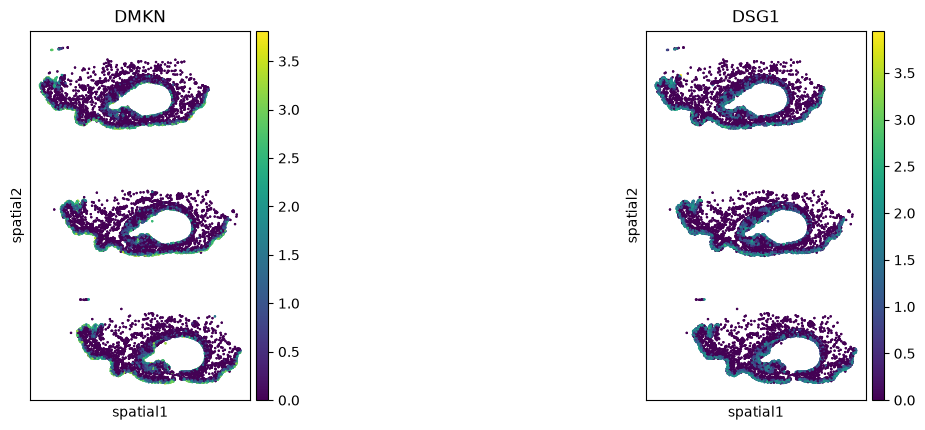

In [20]:
sq.pl.spatial_scatter(
    adata_subsample,
    library_id="spatial",
    color=[
        "DMKN",
        "DSG1",
    ],
    shape=None,
    size=2,
    img=False,
)


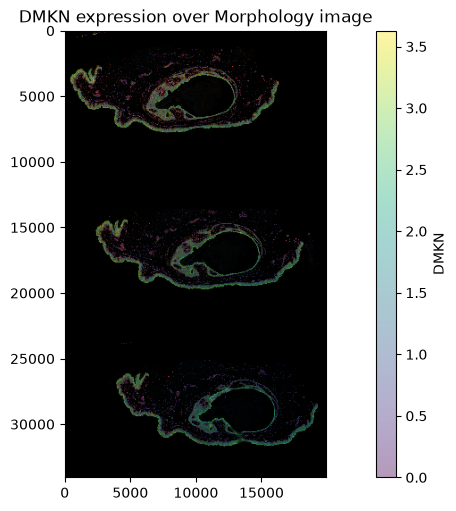

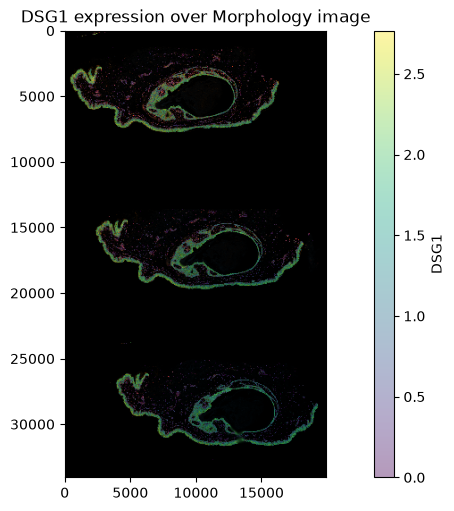

In [24]:
import spatialdata_plot

gene_name = ["DMKN", "DSG1"]
for name in gene_name:
    sdata.pl.render_images("morphology_focus").pl.render_labels(
        "cell_labels",
        color=name,
        table_name="table",
    ).pl.show(
        title=f"{name} expression over Morphology image",
        coordinate_systems="global",
        figsize=(10, 5),
    )